In [15]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

df = pd.read_csv("../data/raw/exoplanets.csv")

df.head()

,Name,Mass (MJ),Radius (RJ),Period (days),Semi-major axis (AU),Temp. (K),Discovery method,Disc. Year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
0,16 Cygni Bb,2.38,NaN,799.5,1.66,NaN,radial vel.,1996.0,68.99,1.04,5750,NaN
1,23 Librae b,1.61,NaN,258.18,0.81,NaN,radial vel.,1999.0,85.46,1.07,5736,NaN
2,47 Ursae Majoris b,2.53,NaN,1078,2.1,NaN,radial vel.,1996.0,45.02,1.08,5892,Proper name Taphao Thong
3,51 Pegasi b,0.46,NaN,4.230785,0.0527,NaN,radial vel.,1995.0,50.45,1.12,5793,Proper name Dimidium; previously informally na...
4,55 Cancri b,0.8306,NaN,14.65152,0.115227,700,radial vel.,1996.0,41.06,0.905,5196,Proper name Galileo


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4855 entries, 0 to 4854
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Name                  4855 non-null   object 
 1   Mass (MJ)             2295 non-null   object 
 2   Radius (RJ)           3700 non-null   object 
 3   Period (days)         4637 non-null   object 
 4   Semi-major axis (AU)  3148 non-null   object 
 5   Temp. (K)             1094 non-null   object 
 6   Discovery method      4855 non-null   object 
 7   Disc. Year            411 non-null    float64
 8   Distance (ly)         4706 non-null   object 
 9   Host star mass (M☉)   4475 non-null   object 
 10  Host star temp. (K)   4513 non-null   object 
 11  Remarks               4502 non-null   object 
dtypes: float64(1), object(11)
memory usage: 455.3+ KB


In [3]:
df.describe()

,Disc. Year
count,411.000000
mean,2005.313869
std,3.639389
min,1988.000000
25%,2003.000000
50%,2006.000000
75%,2008.000000
max,2009.000000


In [4]:
df.isna().sum().sort_values(ascending=False)

Disc. Year              4444
Temp. (K)               3761
Mass (MJ)               2560
Semi-major axis (AU)    1707
Radius (RJ)             1155
Host star mass (M☉)      380
Remarks                  353
Host star temp. (K)      342
Period (days)            218
Distance (ly)            149
Name                       0
Discovery method           0
dtype: int64

In [32]:
# Remove any leading/trailing spaces from column names
df.columns = df.columns.str.strip()
print(df.columns)

Index(['Name', 'Radius (RJ)', 'Period (days)', 'Semi-major axis (AU)',
       'Temp. (K)', 'Discovery method', 'Disc. Year', 'Distance (ly)',
       'Host star mass (M☉)', 'Host star temp. (K)', 'Remarks'],
      dtype='object')


In [35]:
TARGET = "Host star mass (M☉)"
FEATURES = df.drop(columns=[TARGET])
y = df[TARGET]

FEATURES.head()  # Shows first 5 rows of features


,Name,Radius (RJ),Period (days),Semi-major axis (AU),Temp. (K),Discovery method,Disc. Year,Distance (ly),Host star temp. (K),Remarks
0,16 Cygni Bb,NaN,799.5,1.66,NaN,radial vel.,1996.0,68.99,5750,NaN
1,23 Librae b,NaN,258.18,0.81,NaN,radial vel.,1999.0,85.46,5736,NaN
2,47 Ursae Majoris b,NaN,1078,2.1,NaN,radial vel.,1996.0,45.02,5892,Proper name Taphao Thong
3,51 Pegasi b,NaN,4.230785,0.0527,NaN,radial vel.,1995.0,50.45,5793,Proper name Dimidium; previously informally na...
4,55 Cancri b,NaN,14.65152,0.115227,700,radial vel.,1996.0,41.06,5196,Proper name Galileo


In [37]:
from sklearn.impute import SimpleImputer

num_cols = FEATURES.select_dtypes(include=np.number).columns
imputer = SimpleImputer(strategy="median")
FEATURES[num_cols] = imputer.fit_transform(FEATURES[num_cols])

df.head()

,Name,Radius (RJ),Period (days),Semi-major axis (AU),Temp. (K),Discovery method,Disc. Year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
0,16 Cygni Bb,NaN,799.5,1.66,NaN,radial vel.,1996.0,68.99,1.04,5750,NaN
1,23 Librae b,NaN,258.18,0.81,NaN,radial vel.,1999.0,85.46,1.07,5736,NaN
2,47 Ursae Majoris b,NaN,1078,2.1,NaN,radial vel.,1996.0,45.02,1.08,5892,Proper name Taphao Thong
3,51 Pegasi b,NaN,4.230785,0.0527,NaN,radial vel.,1995.0,50.45,1.12,5793,Proper name Dimidium; previously informally na...
4,55 Cancri b,NaN,14.65152,0.115227,700,radial vel.,1996.0,41.06,0.905,5196,Proper name Galileo


In [39]:
print(df.head())

                 Name Radius (RJ) Period (days) Semi-major axis (AU)  \
0         16 Cygni Bb         NaN         799.5                 1.66   
1         23 Librae b         NaN        258.18                 0.81   
2  47 Ursae Majoris b         NaN          1078                  2.1   
3         51 Pegasi b         NaN      4.230785               0.0527   
4         55 Cancri b         NaN      14.65152             0.115227   

  Temp. (K) Discovery method  Disc. Year Distance (ly) Host star mass (M☉)  \
0       NaN      radial vel.      1996.0         68.99                1.04   
1       NaN      radial vel.      1999.0         85.46                1.07   
2       NaN      radial vel.      1996.0         45.02                1.08   
3       NaN      radial vel.      1995.0         50.45                1.12   
4       700      radial vel.      1996.0         41.06               0.905   

  Host star temp. (K)                                            Remarks  
0                5750  

In [41]:
cat_cols = FEATURES.select_dtypes(include="object").columns
FEATURES[cat_cols] = FEATURES[cat_cols].fillna("Unknown")

df.head()


,Name,Radius (RJ),Period (days),Semi-major axis (AU),Temp. (K),Discovery method,Disc. Year,Distance (ly),Host star mass (M☉),Host star temp. (K),Remarks
0,16 Cygni Bb,NaN,799.5,1.66,NaN,radial vel.,1996.0,68.99,1.04,5750,NaN
1,23 Librae b,NaN,258.18,0.81,NaN,radial vel.,1999.0,85.46,1.07,5736,NaN
2,47 Ursae Majoris b,NaN,1078,2.1,NaN,radial vel.,1996.0,45.02,1.08,5892,Proper name Taphao Thong
3,51 Pegasi b,NaN,4.230785,0.0527,NaN,radial vel.,1995.0,50.45,1.12,5793,Proper name Dimidium; previously informally na...
4,55 Cancri b,NaN,14.65152,0.115227,700,radial vel.,1996.0,41.06,0.905,5196,Proper name Galileo


In [42]:
# 1. Reload the data to be sure
df = pd.read_csv("../data/raw/exoplanets.csv")

# 2. Define TARGET and FEATURES
TARGET = "Mass (MJ)"
y = df[TARGET]
FEATURES = df.drop(columns=[TARGET])

# 3. Handle missing values (Imputation)
from sklearn.impute import SimpleImputer
import numpy as np

# Select numeric columns only
num_cols = FEATURES.select_dtypes(include=np.number).columns

# Fill missing values with the median
imputer = SimpleImputer(strategy="median")
FEATURES[num_cols] = imputer.fit_transform(FEATURES[num_cols])

# 4. Check if missing values are gone
print("Missing values in FEATURES after imputation:")
print(FEATURES[num_cols].isna().sum().sum())

Missing values in FEATURES after imputation:
0


In [48]:
from sklearn.preprocessing import OneHotEncoder

FEATURES = pd.get_dummies(FEATURES, columns=cat_cols, drop_first=True)


KeyError: "None of [Index(['Name', 'Radius (RJ)', 'Period (days)', 'Semi-major axis (AU)',\n       'Temp. (K)', 'Discovery method', 'Distance (ly)', 'Host star temp. (K)',\n       'Remarks'],\n      dtype='object')] are in the [columns]"

In [49]:
# 1. Reload and clean data
df = pd.read_csv("../data/raw/exoplanets.csv")
df.columns = df.columns.str.strip()  # <--- CRITICAL FIX

# 2. Define Target and Features
TARGET = "Mass (MJ)"
y = df[TARGET]
FEATURES = df.drop(columns=[TARGET])

# 3. Define column types
num_cols = FEATURES.select_dtypes(include=np.number).columns
cat_cols = FEATURES.select_dtypes(include="object").columns

# 4. Impute missing numeric values
from sklearn.impute import SimpleImputer
import numpy as np
imputer = SimpleImputer(strategy="median")
FEATURES[num_cols] = imputer.fit_transform(FEATURES[num_cols])

# 5. Fill missing categorical values
FEATURES[cat_cols] = FEATURES[cat_cols].fillna("Unknown")

# 6. One-Hot Encode
from sklearn.preprocessing import OneHotEncoder
print("Starting One-Hot Encoding...")
FEATURES = pd.get_dummies(FEATURES, columns=cat_cols, drop_first=True)

print("Success! Final shape:", FEATURES.shape)
FEATURES.head()

Starting One-Hot Encoding...
Success! Final shape: (4855, 20819)


,Disc. Year,Name_11 Comae Berenices b,Name_11 Ursae Minoris b,Name_14 Andromedae b,Name_14 Herculis b,Name_14 Herculis c,Name_16 Cygni Bb,Name_18 Delphini b,Name_1RXS J160929.1-210524 b,Name_23 Librae b,...,Remarks_[9] Proper name Mulchatna,Remarks_[9] Proper name Naron,Remarks_[9] Proper name Victoriapeak,Remarks_an ultra-short-period Jupiter orbiting a bright (V=11.1 mag) K4-dwarf.[23][24][25][26],Remarks_false positive,Remarks_habitable zone[90],Remarks_member of AB Doradus moving group[2],Remarks_member of Hyades (star cluster)[22][23],Remarks_one more suspected planet in system[59],Remarks_unconfirmed as in 2020
0,1996.0,False,False,False,False,False,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,1999.0,False,False,False,False,False,False,False,False,True,...,False,False,False,False,False,False,False,False,False,False
2,1996.0,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,1995.0,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,1996.0,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [50]:
from sklearn.model_selection import train_test_split

print("Original shape:", FEATURES.shape)

# 1. Force target to be numeric (errors become NaN)
y_numeric = pd.to_numeric(y, errors='coerce')

# 2. Drop rows where the target is missing (we can't train on them)
#    We use the index to keep X and y aligned
valid_indices = y_numeric.dropna().index
X_clean = FEATURES.loc[valid_indices]
y_clean = y_numeric.loc[valid_indices]

print(f"Shape after dropping missing targets: {X_clean.shape}")

# 3. Perform the split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42
)

print("Split successful!")
print(f"Training set: {X_train.shape}")
print(f"Test set: {X_test.shape}")

Original shape: (4855, 20819)
Shape after dropping missing targets: (1474, 20819)
Split successful!
Training set: (1179, 20819)
Test set: (295, 20819)


In [51]:
from sklearn.preprocessing import StandardScaler

# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data (do NOT fit again)
X_test_scaled = scaler.transform(X_test)

# Optional: Convert back to DataFrame to keep column names
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X_train.columns, index=X_train.index)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X_test.columns, index=X_test.index)

print("Feature scaling complete!")
print("Train mean:", X_train_scaled.mean().mean())  # Should be close to 0
print("Train std:", X_train_scaled.std().mean())    # Should be close to 1
X_train_scaled.head()

Feature scaling complete!
Train mean: -4.894287847822489e-18
Train std: 0.29105962522121276


,Disc. Year,Name_11 Comae Berenices b,Name_11 Ursae Minoris b,Name_14 Andromedae b,Name_14 Herculis b,Name_14 Herculis c,Name_16 Cygni Bb,Name_18 Delphini b,Name_1RXS J160929.1-210524 b,Name_23 Librae b,...,Remarks_[9] Proper name Mulchatna,Remarks_[9] Proper name Naron,Remarks_[9] Proper name Victoriapeak,Remarks_an ultra-short-period Jupiter orbiting a bright (V=11.1 mag) K4-dwarf.[23][24][25][26],Remarks_false positive,Remarks_habitable zone[90],Remarks_member of AB Doradus moving group[2],Remarks_member of Hyades (star cluster)[22][23],Remarks_one more suspected planet in system[59],Remarks_unconfirmed as in 2020
1186,0.095831,-0.029136,-0.029136,-0.029136,-0.029136,0.0,-0.029136,-0.029136,0.0,-0.029136,...,-0.029136,-0.029136,-0.029136,0.0,0.0,0.0,0.0,0.0,0.0,-0.029136
258,-0.410829,-0.029136,-0.029136,-0.029136,-0.029136,0.0,-0.029136,-0.029136,0.0,-0.029136,...,-0.029136,-0.029136,-0.029136,0.0,0.0,0.0,0.0,0.0,0.0,-0.029136
1900,0.095831,-0.029136,-0.029136,-0.029136,-0.029136,0.0,-0.029136,-0.029136,0.0,-0.029136,...,-0.029136,-0.029136,-0.029136,0.0,0.0,0.0,0.0,0.0,0.0,-0.029136
682,0.095831,-0.029136,-0.029136,-0.029136,-0.029136,0.0,-0.029136,-0.029136,0.0,-0.029136,...,-0.029136,-0.029136,-0.029136,0.0,0.0,0.0,0.0,0.0,0.0,-0.029136
4672,0.095831,-0.029136,-0.029136,-0.029136,-0.029136,0.0,-0.029136,-0.029136,0.0,-0.029136,...,-0.029136,-0.029136,-0.029136,0.0,0.0,0.0,0.0,0.0,0.0,-0.029136


In [52]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 1. Initialize the model
model = LinearRegression()

# 2. Train on the scaled training data
model.fit(X_train_scaled, y_train)

# 3. Predict on the test set
y_pred = model.predict(X_test_scaled)

# 4. Evaluate performance
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Baseline Model Performance (Linear Regression):")
print(f"Mean Squared Error: {mse:.4f}")
print(f"R^2 Score: {r2:.4f}")

Baseline Model Performance (Linear Regression):
Mean Squared Error: 18.6087
R^2 Score: 0.2248


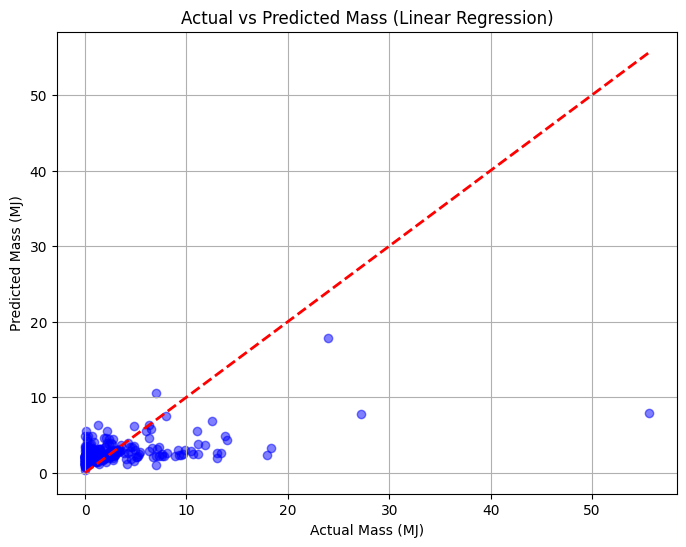

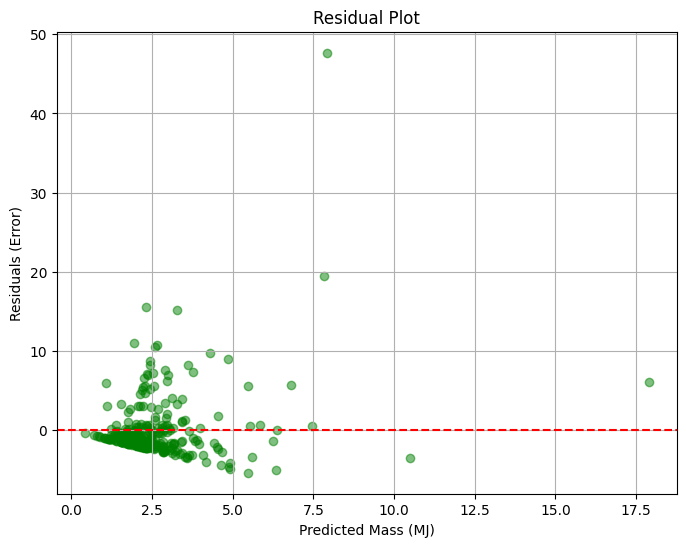

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5, color='blue')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)  # Perfect prediction line
plt.xlabel('Actual Mass (MJ)')
plt.ylabel('Predicted Mass (MJ)')
plt.title('Actual vs Predicted Mass (Linear Regression)')
plt.grid(True)
plt.show()

# Residual plot (Actual - Predicted)
residuals = y_test - y_pred
plt.figure(figsize=(8, 6))
plt.scatter(y_pred, residuals, alpha=0.5, color='green')
plt.axhline(0, color='r', linestyle='--')
plt.xlabel('Predicted Mass (MJ)')
plt.ylabel('Residuals (Error)')
plt.title('Residual Plot')
plt.grid(True)
plt.show()